In [1]:
import torch
import random
import os

os.environ["GEOMSTATS_BACKEND"] = "pytorch"
os.environ["SCIPY_ARRAY_API"] = "1"

import numpy as np
import matplotlib.pyplot as plt

from lib_pca.utils_sqrtm import sqrtm
from xp_2d import get_plot_pca, get_plot_uapca, get_plot_lifted_pca

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# For deterministic CUDA operations
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Example Mixture of Gaussian

In [3]:
m1, m2, m3, m4 = [-1., 1.], [1., -1.], [1.5, 2.], [-1.5, -2.]
means = torch.tensor([m1, m2, m3, m4])

Sigma0 = torch.tensor([[1, -0.5], [-0.5, 1]])
Sigma1 = torch.tensor([[1, -0.5], [-0.5, 1]])
Sigma2 = torch.tensor([[1, -0.4], [-0.4, 2.4]])
Sigma4 = 0.5 * torch.tensor([[1, -0.5], [-0.5, 1]])

s = 0.05

Sigmas = s * torch.stack([Sigma0, Sigma1, Sigma2, Sigma4])

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

colors = ["red", "blue", "green", "purple"]

INFO:2026-09-14 15:57:17,207:jax._src.xla_bridge:812: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


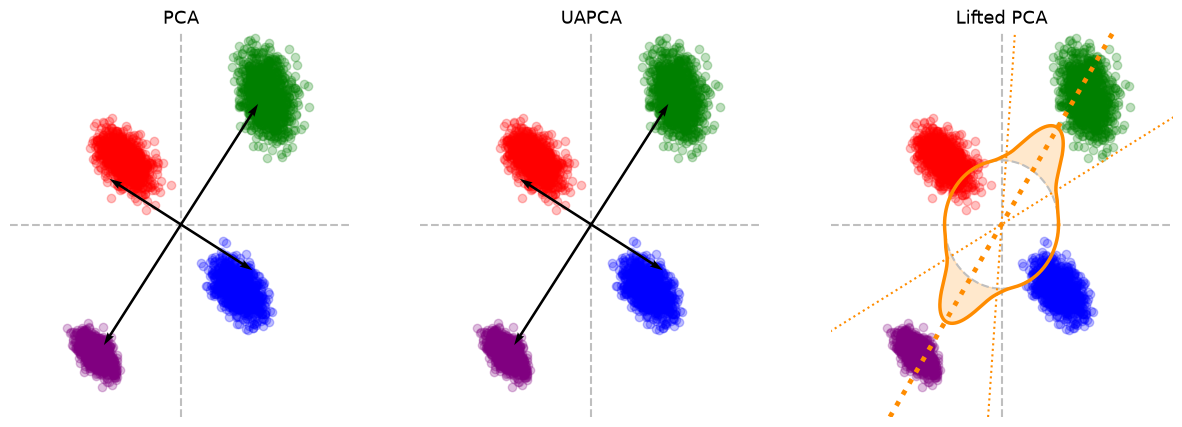

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

get_plot_pca(samples, ax=axes[0], xmin=-3, xmax=3, ymin=-3, ymax=3, colors=colors)
get_plot_uapca(samples, ax=axes[1], xmin=-3, xmax=3, ymin=-3, ymax=3, colors=colors, value_barycenter=False)
get_plot_lifted_pca(samples, ax=axes[2], xmin=-3, xmax=3, ymin=-3, ymax=3, colors=colors, value_barycenter=False)

plt.show()

## Gaussian Mixture with Bigger covariances

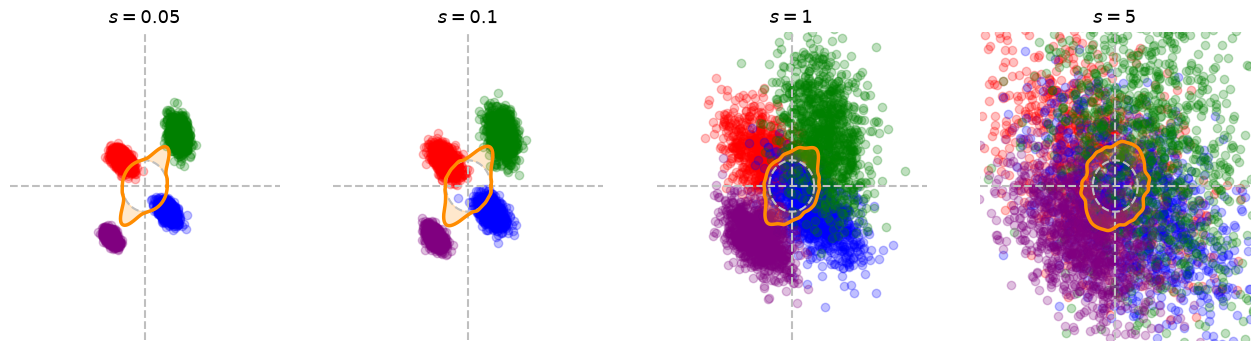

In [5]:
colors = ["red", "blue", "green", "purple"]

m1, m2, m3, m4 = [-1., 1.], [1., -1.], [1.5, 2.], [-1.5, -2.]
means = torch.tensor([m1, m2, m3, m4])

Sigma0 = torch.tensor([[1, -0.5], [-0.5, 1]])
Sigma1 = torch.tensor([[1, -0.5], [-0.5, 1]])
Sigma2 = torch.tensor([[1, -0.4], [-0.4, 2.4]])
Sigma4 = 0.5 * torch.tensor([[1, -0.5], [-0.5, 1]])

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, s in enumerate([0.05, 0.1, 1, 5]):
    Sigmas = s * torch.stack([Sigma0, Sigma1, Sigma2, Sigma4])

    n = 1000
    d = 2
    samples = torch.zeros((len(means), n, d))
    for k in range(len(means)):
        samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

    get_plot_lifted_pca(samples, ax=axes[i], xmin=-6, xmax=6, ymin=-6, ymax=6, colors=colors, plot_ci=False, title=r"$s=$"+str(s))


plt.savefig("./Figures/Lifted_PCA_Mixture_Evo_Cov.pdf", format="pdf", bbox_inches="tight")

plt.show()

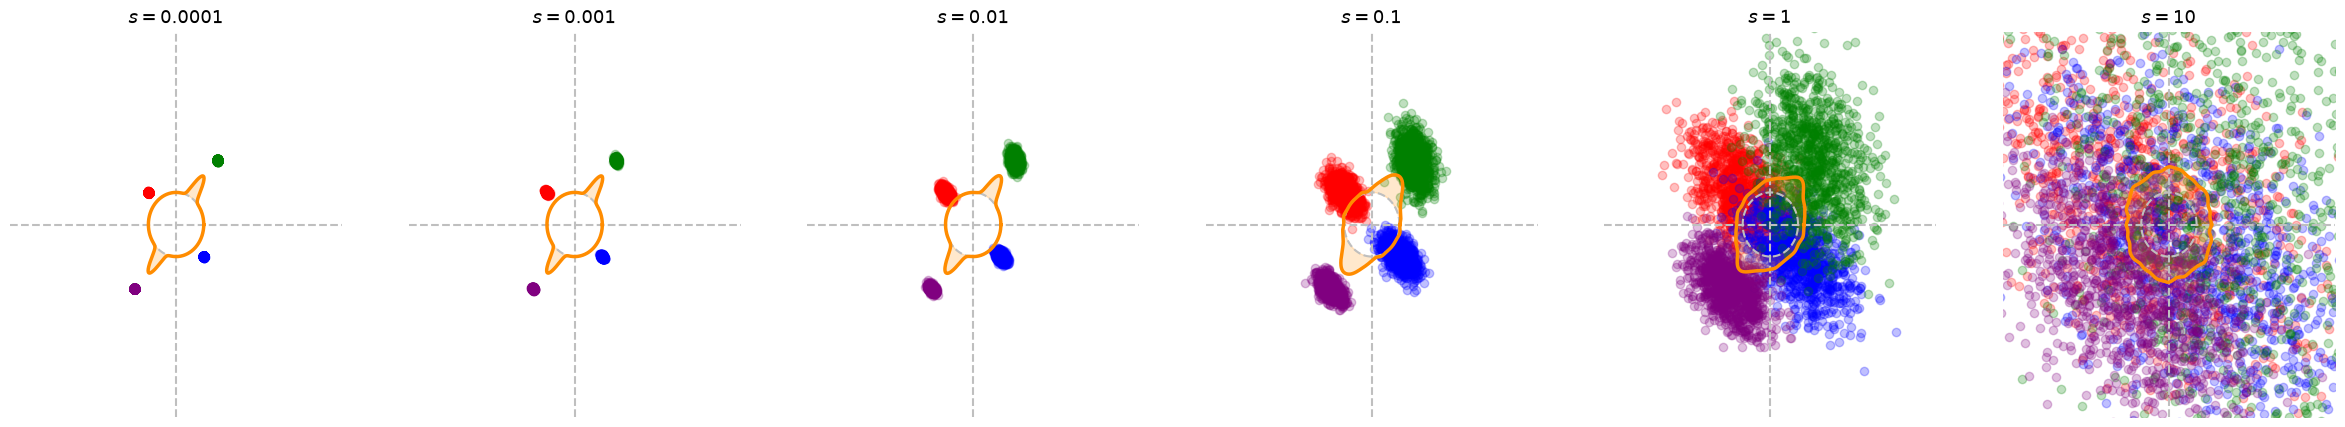

In [24]:
colors = ["red", "blue", "green", "purple"]

m1, m2, m3, m4 = [-1., 1.], [1., -1.], [1.5, 2.], [-1.5, -2.]
means = torch.tensor([m1, m2, m3, m4])

Sigma0 = torch.tensor([[1, -0.5], [-0.5, 1]])
Sigma1 = torch.tensor([[1, -0.5], [-0.5, 1]])
Sigma2 = torch.tensor([[1, -0.4], [-0.4, 2.4]])
Sigma4 = 0.5 * torch.tensor([[1, -0.5], [-0.5, 1]])

fig, axes = plt.subplots(1, 6, figsize=(30, 5))

for i, s in enumerate([0.0001, 0.001, 0.01, 0.1, 1, 10]):
    Sigmas = s * torch.stack([Sigma0, Sigma1, Sigma2, Sigma4])

    n = 1000
    d = 2
    samples = torch.zeros((len(means), n, d))
    for k in range(len(means)):
        samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

    get_plot_lifted_pca(samples, ax=axes[i], xmin=-6, xmax=6, ymin=-6, ymax=6, colors=colors, plot_ci=False, title=r"$s=$"+str(s))


# plt.savefig("./Figures/Lifted_PCA_Mixture_Evo_Cov.pdf", format="pdf", bbox_inches="tight")
# fig.subplots_adjust(wspace=0.05)
plt.show()

## One Clear Axis

In [6]:
m1, m2, m3, m4 = [0, -2], [0, -1], [0, 0], [0, 1]
means = torch.tensor([m1, m2, m3, m4])

Sigma = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigmas = torch.stack([Sigma for i in range(len(means))])

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

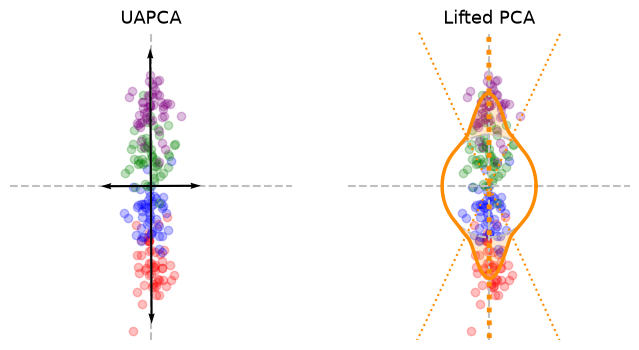

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

get_plot_uapca(samples, ax=axes[0], xmin=-3, xmax=3, ymin=-3, ymax=3, colors=colors)
get_plot_lifted_pca(samples, ax=axes[1], xmin=-3, xmax=3, ymin=-3, ymax=3, colors=colors)

plt.show()

INFO: Substituting symbol T from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol T from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol T from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol T from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol T from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol T from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol T from STIXNonUnicode
INFO: Substituting symbol C from STIXNonUnicode
INFO: Substituting symbol C from STIXNon

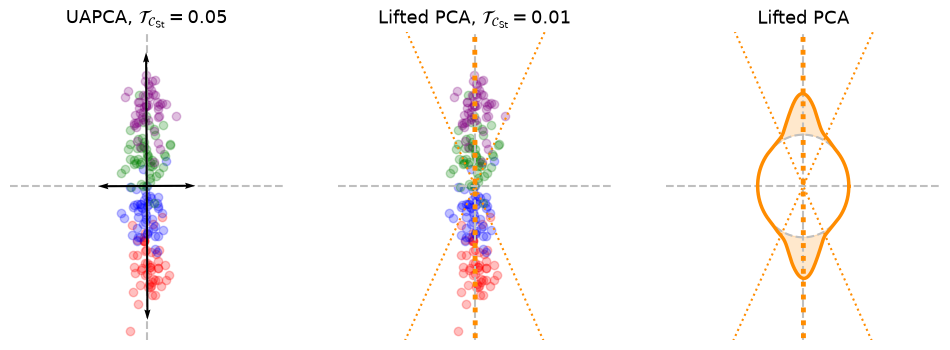

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

get_plot_uapca(samples, ax=axes[0], xmin=-3, xmax=3, ymin=-3, ymax=3, colors=colors, value_barycenter=True)
get_plot_lifted_pca(samples, ax=axes[1], xmin=-3, xmax=3, ymin=-3, ymax=3, colors=colors, plot_circle=False, value_barycenter=True)
get_plot_lifted_pca(samples, ax=axes[2], xmin=-3, xmax=3, ymin=-3, ymax=3, colors=colors, plot_samples=False)

plt.savefig("./Figures/Comparison_LiftedPCA_vs_UAPCA_one_direction.pdf", format="pdf", bbox_inches="tight")

plt.show()

In [9]:
m1, m2, m3, m4 = [0, -2], [0, -1], [0, 0], [0, 1]
means = torch.tensor([m1, m2, m3, m4])

Sigma = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigmas = torch.stack([Sigma for i in range(len(means))]) * 0.01

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

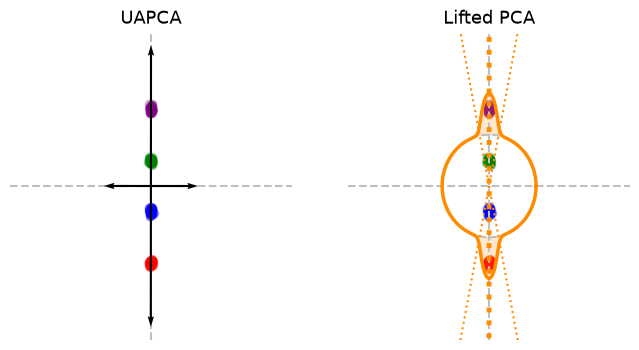

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

get_plot_uapca(samples, ax=axes[0], xmin=-3, xmax=3, ymin=-3, ymax=3, colors=colors)
get_plot_lifted_pca(samples, ax=axes[1], xmin=-3, xmax=3, ymin=-3, ymax=3, colors=colors)

plt.show()

## No Clear Principal Direction

In [11]:
n_distr = 2

means = torch.zeros((n_distr, 2))

Sigma0 = torch.diag(torch.tensor([1.5, 0.01])) # * 0.1
# Sigma1 = torch.diag(torch.tensor([1.5, 0.5])) # * 0.1
Sigma1 = torch.tensor([[0.01, 0.], [0., 1.5]]) # torch.tensor([[0.2, 0.], [0., 3.0]])


Sigmas = torch.stack([Sigma0, Sigma1])

n = 500
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

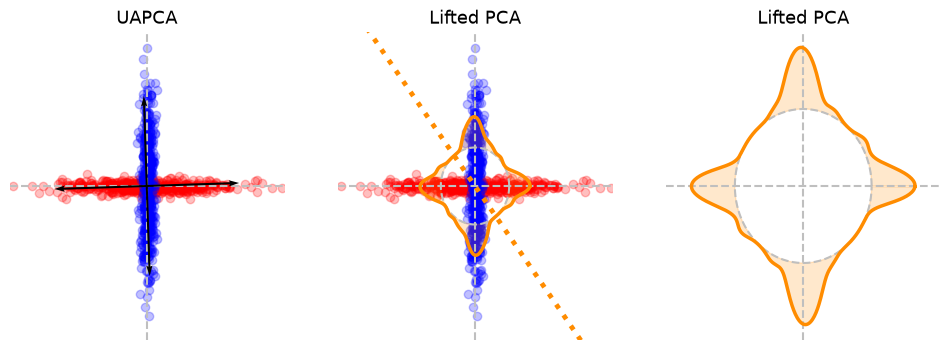

In [12]:
colors = ["red", "blue", "green", "purple"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

get_plot_uapca(samples, ax=axes[0], xmin=-4, xmax=4, ymin=-4, ymax=4, colors=colors)
get_plot_lifted_pca(samples, ax=axes[1], xmin=-4, xmax=4, ymin=-4, ymax=4, colors=colors, plot_ci=False, plot_bary=True)

# get_plot_lifted_pca(samples, ax=axes[1], xmin=-4, xmax=4, ymin=-4, ymax=4, colors=colors, plot_circle=False, value_barycenter=False)
get_plot_lifted_pca(samples, ax=axes[2], xmin=-2, xmax=2, ymin=-2, ymax=2, colors=colors, plot_samples=False, plot_ci=False)

plt.savefig("./Figures/Comparison_LiftedPCA_vs_UAPCA_two_directions.pdf", format="pdf", bbox_inches="tight")

plt.show()
